# Đánh giá theo giới

## Đọc dự đoán

Nhóm theo giới gốc trong dự đoán ngoài; thiếu giới là nhóm riêng. Dùng ngưỡng Youden NHANES của từng mô hình cho cả hai năm và mọi nhóm; metric chưa áp trọng số khảo sát.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_dir = Path.cwd()
if not (project_dir / "src").is_dir():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))
from src.utils import get_binary_group_metrics, get_sex_metric_gaps, save_png, get_manifest_artifact_hash

final_run_id = "54c463bbe9079503"
source_dir = project_dir / "results/external_validation" / final_run_id
results_dir = project_dir / "results/fairness" / final_run_id
figures_dir = project_dir / "results/figures/fairness" / final_run_id
results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
external_manifest = json.loads((source_dir / "manifest.json").read_text(encoding="utf-8"))
assert external_manifest["final_run_id"] == final_run_id
assert external_manifest["models"] == {"XGBoost": "primary", "LR": "reference"}
thresholds, frozen_hashes = {}, {}
for model in ["XGBoost", "LR"]:
    path = project_dir / "results/final_development" / final_run_id / model / "thresholds.json"
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == get_manifest_artifact_hash(external_manifest["frozen_artifact_sha256"], path, project_dir)
    thresholds[model] = json.loads(path.read_text(encoding="utf-8"))
    assert thresholds[model] == external_manifest["thresholds"][model]
    assert np.isfinite(thresholds[model]["youden"])
    frozen_hashes[str(path)] = digest

predictions, coverage_rows = {}, []
for year, expected_n in [(2015, 440658), (2017, 449219)]:
    for model in ["XGBoost", "LR"]:
        path = source_dir / f"brfss_{year}_{model}_predictions.parquet"
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        assert digest == get_manifest_artifact_hash(external_manifest["output_sha256"], path, project_dir)
        frozen_hashes[str(path)] = digest
        data = pd.read_parquet(path)
        assert len(data) == expected_n and data["year"].eq(year).all()
        assert data["source_row_id"].notna().all() and data["source_row_id"].is_unique
        assert data["diabetes_label"].notna().all() and data["diabetes_label"].isin([0, 1]).all()
        assert data["sex"].dropna().isin([1, 2]).all()
        assert data["probability"].notna().all() and data["probability"].between(0, 1).all()
        assert data["prediction_youden"].notna().all() and data["prediction_youden"].isin([0, 1]).all()
        np.testing.assert_array_equal(
            data["prediction_youden"],
            data["probability"].ge(thresholds[model]["youden"]).astype(int),
        )
        predictions[(year, model)] = data
    columns = ["year", "source_row_id", "diabetes_label", "sex"]
    pd.testing.assert_frame_equal(predictions[(year, "XGBoost")][columns],
                                  predictions[(year, "LR")][columns])
    data = predictions[(year, "XGBoost")]
    row = {"year": year, "Nam": int(data["sex"].eq(1).sum()),
           "Nữ": int(data["sex"].eq(2).sum()), "Thiếu giới": int(data["sex"].isna().sum()),
           "toàn mẫu": len(data)}
    assert row["Nam"] + row["Nữ"] + row["Thiếu giới"] == expected_n
    coverage_rows.append(row)
coverage = pd.DataFrame(coverage_rows)
coverage.to_csv(results_dir / "sex_counts.csv", index=False)
display(coverage)
display(pd.DataFrame([{"model": model, "youden_nhanes": item["youden"]}
                      for model, item in thresholds.items()]))


,year,Nam,Nữ,Thiếu giới,toàn mẫu
0,2015,186528,254130,0,440658
1,2017,198325,250618,276,449219


,model,youden_nhanes
0,XGBoost,0.489961
1,LR,0.506633


## Metric từng nhóm

TPR là sensitivity; tỷ số có mẫu số 0 là NA. ROC-AUC cần đủ hai nhãn, AP cần có nhãn 1; nhóm rỗng có số đếm 0 và metric NA.

In [2]:
empty = get_binary_group_metrics([], [], [])
assert empty["n"] == 0 and all(pd.isna(empty[key]) for key in [
    "positive_rate", "tpr", "fpr", "specificity", "ppv", "npv", "f1",
    "roc_auc", "average_precision", "brier", "predicted_positive_rate",
])
negative_only = get_binary_group_metrics([0, 0], [0.2, 0.4], [0, 0])
assert pd.isna(negative_only["tpr"]) and pd.isna(negative_only["ppv"])
assert pd.isna(negative_only["f1"]) and pd.isna(negative_only["roc_auc"])
assert pd.isna(negative_only["average_precision"]) and negative_only["specificity"] == 1
positive_only = get_binary_group_metrics([1, 1], [0.6, 0.8], [1, 1])
assert pd.isna(positive_only["fpr"]) and pd.isna(positive_only["specificity"])
assert pd.isna(positive_only["npv"]) and pd.isna(positive_only["roc_auc"])
assert positive_only["average_precision"] == 1 and positive_only["tpr"] == 1

group_rows = []
for (year, model), data in predictions.items():
    masks = {
        "Nam": data["sex"].eq(1).fillna(False),
        "Nữ": data["sex"].eq(2).fillna(False),
        "Thiếu giới": data["sex"].isna(),
    }
    assert np.all(np.stack([mask.to_numpy(dtype=bool) for mask in masks.values()]).sum(axis=0) == 1)
    for group, mask in masks.items():
        subset = data.loc[mask]
        metrics = get_binary_group_metrics(subset["diabetes_label"], subset["probability"],
                                           subset["prediction_youden"])
        group_rows.append({"year": year, "model": model, "sex_group": group,
                           "threshold": thresholds[model]["youden"], **metrics})
group_metrics = pd.DataFrame(group_rows)
external_metrics = pd.read_csv(source_dir / "threshold_metrics.csv").query("threshold_name == 'youden'")
for (year, model), groups in group_metrics.groupby(["year", "model"]):
    total = external_metrics.query("year == @year and model == @model").iloc[0]
    for column in ["n", "n_positive", "tn", "fp", "fn", "tp"]:
        assert groups[column].sum() == total[column]
    assert groups["n_negative"].sum() == total["n"] - total["n_positive"]
    assert groups["threshold"].nunique() == 1 and groups["threshold"].iloc[0] == thresholds[model]["youden"]
group_metrics.to_csv(results_dir / "sex_group_metrics.csv", index=False, na_rep="NA")
keys = ["year", "model", "sex_group"]
display(group_metrics[keys + ["n", "n_positive", "n_negative", "positive_rate", "tn", "fp", "fn", "tp"]]
        .round(4).astype(object).fillna("NA"))
display(group_metrics[keys + ["tpr", "fpr", "specificity", "ppv", "npv", "f1", "predicted_positive_rate"]]
        .round(4).astype(object).fillna("NA"))
display(group_metrics[keys + ["roc_auc", "average_precision", "brier"]]
        .round(4).astype(object).fillna("NA"))


,year,model,sex_group,n,n_positive,n_negative,positive_rate,tn,fp,fn,tp
0,2015,XGBoost,Nam,186528,25404,161124,0.1362,99280,61844,5324,20080
1,2015,XGBoost,Nữ,254130,31852,222278,0.1253,163643,58635,10978,20874
2,2015,XGBoost,Thiếu giới,0,0,0,NA,0,0,0,0
3,2015,LR,Nam,186528,25404,161124,0.1362,110761,50363,7117,18287
4,2015,LR,Nữ,254130,31852,222278,0.1253,169561,52717,12448,19404
5,2015,LR,Thiếu giới,0,0,0,NA,0,0,0,0
6,2017,XGBoost,Nam,198325,27457,170868,0.1384,105298,65570,5646,21811
7,2017,XGBoost,Nữ,250618,32944,217674,0.1315,158946,58728,11137,21807
8,2017,XGBoost,Thiếu giới,276,39,237,0.1413,155,82,13,26
9,2017,LR,Nam,198325,27457,170868,0.1384,117053,53815,7556,19901


,year,model,sex_group,tpr,fpr,specificity,ppv,npv,f1,predicted_positive_rate
0,2015,XGBoost,Nam,0.7904,0.3838,0.6162,0.2451,0.9491,0.3742,0.4392
1,2015,XGBoost,Nữ,0.6553,0.2638,0.7362,0.2625,0.9371,0.3749,0.3129
2,2015,XGBoost,Thiếu giới,NA,NA,NA,NA,NA,NA,NA
3,2015,LR,Nam,0.7198,0.3126,0.6874,0.2664,0.9396,0.3889,0.368
4,2015,LR,Nữ,0.6092,0.2372,0.7628,0.269,0.9316,0.3733,0.2838
5,2015,LR,Thiếu giới,NA,NA,NA,NA,NA,NA,NA
6,2017,XGBoost,Nam,0.7944,0.3837,0.6163,0.2496,0.9491,0.3799,0.4406
7,2017,XGBoost,Nữ,0.6619,0.2698,0.7302,0.2708,0.9345,0.3843,0.3213
8,2017,XGBoost,Thiếu giới,0.6667,0.346,0.654,0.2407,0.9226,0.3537,0.3913
9,2017,LR,Nam,0.7248,0.315,0.685,0.27,0.9394,0.3934,0.3717


,year,model,sex_group,roc_auc,average_precision,brier
0,2015,XGBoost,Nam,0.7734,0.3281,0.2081
1,2015,XGBoost,Nữ,0.7706,0.307,0.1679
2,2015,XGBoost,Thiếu giới,NA,NA,NA
3,2015,LR,Nam,0.7743,0.3241,0.1961
4,2015,LR,Nữ,0.7685,0.304,0.1715
5,2015,LR,Thiếu giới,NA,NA,NA
6,2017,XGBoost,Nam,0.7746,0.3347,0.2071
7,2017,XGBoost,Nữ,0.768,0.3131,0.1703
8,2017,XGBoost,Thiếu giới,0.747,0.3319,0.1995
9,2017,LR,Nam,0.7766,0.3407,0.1948


## Chênh lệch Nam − Nữ

Chênh lệch TPR, FPR, PPV và tỷ lệ dự đoán dương tính bằng điểm phần trăm. Equalized odds gap là `max(|TPR gap|, |FPR gap|)`, nhận NA nếu một thành phần không xác định.

In [3]:
sex_gaps = get_sex_metric_gaps(group_metrics)
gap_columns = ["tpr_gap_pp", "fpr_gap_pp", "ppv_gap_pp", "predicted_positive_rate_gap_pp"]
for _, row in sex_gaps.iterrows():
    groups = group_metrics.query("year == @row.year and model == @row.model").set_index("sex_group")
    for metric, gap in zip(["tpr", "fpr", "ppv", "predicted_positive_rate"], gap_columns):
        expected = (groups.loc["Nam", metric] - groups.loc["Nữ", metric]) * 100
        np.testing.assert_allclose(row[gap], expected, equal_nan=True)
    expected_eo = np.max(np.abs([row["tpr_gap_pp"], row["fpr_gap_pp"]]))
    np.testing.assert_allclose(row["equalized_odds_gap_pp"], expected_eo, equal_nan=True)
missing_component = group_metrics.copy()
missing_component.loc[missing_component["sex_group"].eq("Nam"), "tpr"] = np.nan
assert get_sex_metric_gaps(missing_component)["equalized_odds_gap_pp"].isna().all()
sex_gaps.to_csv(results_dir / "sex_gaps_pp.csv", index=False, na_rep="NA")
display(sex_gaps.round(2).astype(object).fillna("NA"))


,year,model,tpr_gap_pp,fpr_gap_pp,ppv_gap_pp,predicted_positive_rate_gap_pp,equalized_odds_gap_pp
0,2015,XGBoost,13.51,12.0,-1.74,12.63,13.51
1,2015,LR,11.07,7.54,-0.27,8.42,11.07
2,2017,XGBoost,13.24,11.39,-2.12,11.92,13.24
3,2017,LR,10.37,7.01,-0.75,7.74,10.37


## TPR và FPR theo giới

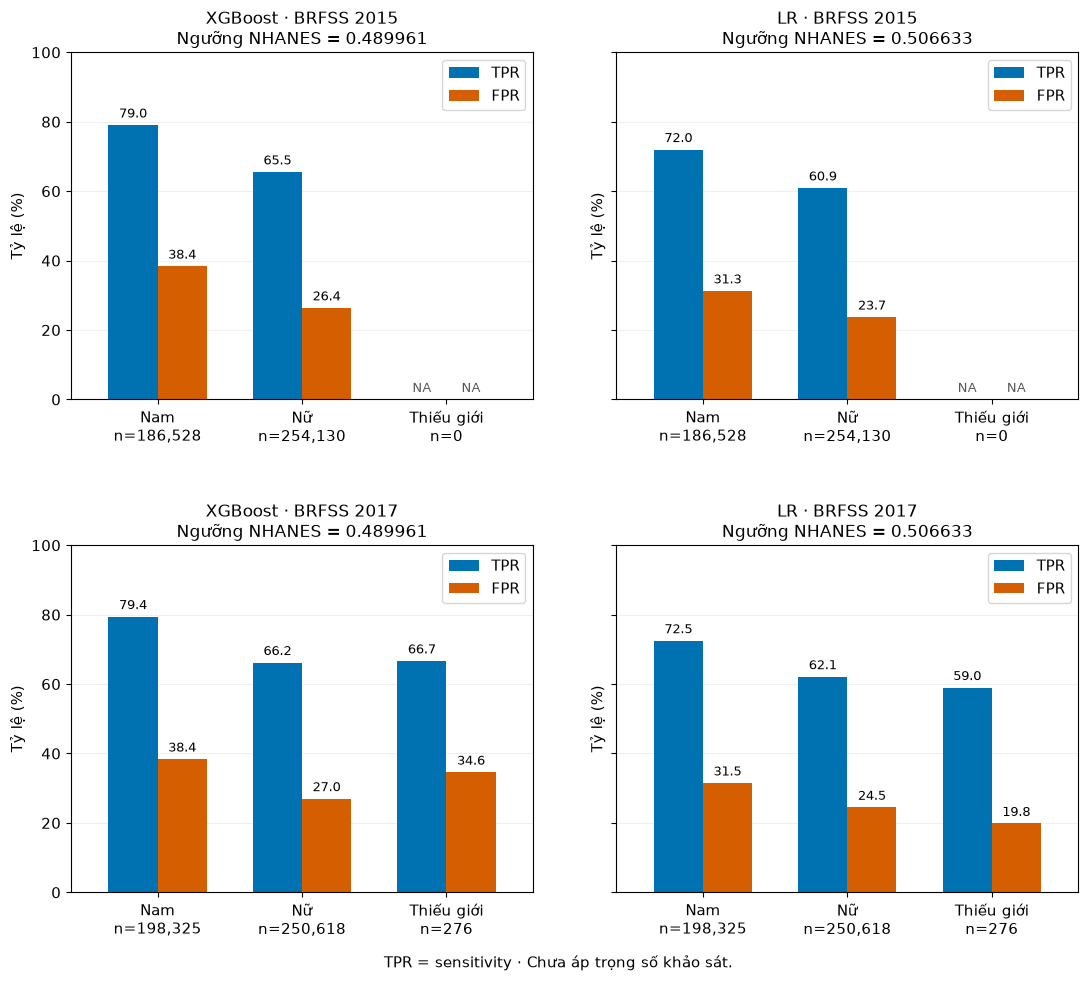

In [4]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.titlesize": 12, "axes.labelsize": 11})
fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharey=True)
group_order = ["Nam", "Nữ", "Thiếu giới"]
positions = np.arange(3)
width = 0.34
for i, year in enumerate([2015, 2017]):
    for j, model in enumerate(["XGBoost", "LR"]):
        ax = axes[i, j]
        groups = group_metrics.query("year == @year and model == @model").set_index("sex_group").loc[group_order]
        for metric, label, offset, color in [
            ("tpr", "TPR", -width / 2, "#0072B2"),
            ("fpr", "FPR", width / 2, "#D55E00"),
        ]:
            values = groups[metric].to_numpy(dtype=float) * 100
            ax.bar(positions + offset, values, width, label=label, color=color)
            for x, value in zip(positions + offset, values):
                if np.isfinite(value):
                    ax.text(x, value + 1.3, f"{value:.1f}", ha="center", va="bottom", fontsize=9)
                else:
                    ax.text(x, 1.3, "NA", ha="center", va="bottom", fontsize=9, color="#555555")
        ax.set(xticks=positions,
               xticklabels=[f"{group}\nn={int(groups.loc[group, 'n']):,}" for group in group_order],
               title=f"{model} · BRFSS {year}\nNgưỡng NHANES = {thresholds[model]['youden']:.6f}",
               xlim=(-0.6, 2.6), ylim=(0, 100), ylabel="Tỷ lệ (%)")
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)
        ax.legend(loc="upper right")
fig.subplots_adjust(bottom=0.10, top=0.94, hspace=0.42, wspace=0.18)
fig.text(0.5, 0.025, "TPR = sensitivity · Chưa áp trọng số khảo sát.", ha="center")
figure_paths = []
figure_paths.append(save_png(fig, figures_dir / "sex_tpr_fpr.png"))
plt.show()
plt.close(fig)


## Nhận xét

Nam có TPR/FPR và tỷ lệ dự đoán dương cao hơn, còn PPV thấp hơn Nữ ở cả hai mô hình và hai năm. Các chênh lệch mô tả chưa có CI/kiểm định, không đủ kết luận nguyên nhân hay phân biệt đối xử.

In [5]:
for filename, digest in frozen_hashes.items():
    assert hashlib.sha256(Path(filename).read_bytes()).hexdigest() == digest
pd.testing.assert_frame_equal(
    pd.read_csv(results_dir / "sex_group_metrics.csv"), group_metrics,
    check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-15,
)
pd.testing.assert_frame_equal(
    pd.read_csv(results_dir / "sex_gaps_pp.csv"), sex_gaps,
    check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-15,
)
manifest = {
    "final_run_id": final_run_id, "source": "saved external BRFSS predictions",
    "models": {"XGBoost": "primary", "LR": "reference"},
    "groups": {"1": "Nam", "2": "Nữ", "missing": "Thiếu giới"},
    "thresholds": {model: item["youden"] for model, item in thresholds.items()},
    "prediction_rule": "probability >= fixed NHANES Youden threshold, shared across sexes and years",
    "gap_direction": "male - female", "gap_unit": "percentage points",
    "equalized_odds_gap": "max(abs(TPR gap), abs(FPR gap)); NA if either component is NA",
    "undefined_metrics": "NA for zero denominator; AUC requires both classes; AP requires positives; empty group metrics NA",
    "survey_weighted": False, "confidence_intervals": False, "statistical_tests": False,
    "source_sha256": frozen_hashes,
}
output_files = [results_dir / name for name in ["sex_counts.csv", "sex_group_metrics.csv", "sex_gaps_pp.csv"]] + figure_paths
manifest["output_sha256"] = {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in output_files}
(results_dir / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame({"File": [str(p) for p in output_files]}))


,File
0,D:\NCKH Mini\diabetes-project\results\fairness...
1,D:\NCKH Mini\diabetes-project\results\fairness...
2,D:\NCKH Mini\diabetes-project\results\fairness...
3,D:\NCKH Mini\diabetes-project\results\figures\...
4,D:\NCKH Mini\diabetes-project\results\figures\...


## Fairness theo chủng tộc và tuổi

Phân tích bổ sung từ dự đoán BRFSS đã lưu; không huấn luyện lại mô hình. Giữ ngưỡng Youden NHANES của từng mô hình cho mọi nhóm và hai năm. Chủng tộc: White NH, Black NH, Hispanic, Other; Other gộp nhiều nhóm. Tuổi: 18-39, 40-59, 60-79, 80+; dữ liệu đã chặn tuổi trên ở 80.

Nhóm thiếu được báo cáo riêng, không lấy giá trị đã điền thiếu để phân nhóm. Gap nhiều nhóm = max − min, đơn vị điểm phần trăm; khác với gap Nam − Nữ có dấu ở phần trước. Equalized odds gap = max(khoảng TPR, khoảng FPR). Nếu bất kỳ nhóm so sánh nào không xác định metric thì gap tương ứng là NA.

Chưa áp trọng số khảo sát, CI hay kiểm định. Chênh lệch mô tả chưa chứng minh phân biệt đối xử; cần xét tỷ lệ bệnh, nhãn tự khai BRFSS và khả năng tiếp cận chẩn đoán. Không yêu cầu tỷ lệ dự đoán dương bằng nhau giữa các nhóm tuổi.


In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_dir = Path.cwd()
if not (project_dir / "src").is_dir():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))
from src.utils import get_binary_group_metrics, get_multigroup_metric_gaps, get_race_age_groups

run_id = "54c463bbe9079503"
source_dir = project_dir / "results/external_validation" / run_id
result_dir = project_dir / "results/fairness" / run_id
figure_dir = project_dir / "results/figures/fairness" / run_id
result_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)
source_manifest = json.loads((source_dir / "manifest.json").read_text(encoding="utf-8"))
assert source_manifest["final_run_id"] == run_id

def checked_hash(path, recorded):
    # Recorded artifacts can come from another checkout on Windows.
    matches = [digest for name, digest in recorded.items()
               if name.replace("\\", "/").rsplit("/", 1)[-1] == path.name]
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert len(matches) == 1 and digest == matches[0], str(path)
    return digest

specs = {
    "race_ethnicity": ["White NH", "Black NH", "Hispanic", "Other"],
    "age": ["18-39", "40-59", "60-79", "80+"],
}


In [2]:
source_hashes, rows = {}, []
for year, expected_n in [(2015, 440658), (2017, 449219)]:
    reference = None
    for model in ["XGBoost", "LR"]:
        path = source_dir / f"brfss_{year}_{model}_predictions.parquet"
        source_hashes[str(path.relative_to(project_dir))] = checked_hash(path, source_manifest["output_sha256"])
        data = pd.read_parquet(path)
        threshold = source_manifest["thresholds"][model]["youden"]
        assert np.isfinite(threshold)
        assert len(data) == expected_n and data["year"].eq(year).all()
        assert data["source_row_id"].notna().all() and data["source_row_id"].is_unique
        assert data["diabetes_label"].notna().all() and data["diabetes_label"].isin([0, 1]).all()
        np.testing.assert_array_equal(data["prediction_youden"], data["probability"].ge(threshold).astype(int))
        alignment = data[["source_row_id", "diabetes_label", "race_ethnicity", "age"]]
        if reference is not None:
            pd.testing.assert_frame_equal(alignment, reference)
        reference = alignment
        labels, checked_specs = get_race_age_groups(data)
        assert checked_specs == specs
        overall = get_binary_group_metrics(data["diabetes_label"], data["probability"], data["prediction_youden"])
        for attribute, groups in specs.items():
            local = []
            assert labels[attribute].isin(groups + ["Missing"]).all()
            for group in groups + ["Missing"]:
                subset = data.loc[labels[attribute].eq(group)]
                metrics = get_binary_group_metrics(subset["diabetes_label"], subset["probability"], subset["prediction_youden"])
                local.append({"year": year, "model": model, "attribute": attribute,
                              "group": group, "threshold": threshold, **metrics})
            for key in ["n", "n_positive", "n_negative", "tn", "fp", "fn", "tp"]:
                assert sum(item[key] for item in local) == overall[key]
            rows.extend(local)



,year,attribute,group,n,n_positive,n_negative,positive_rate
0,2015,race_ethnicity,White NH,335611,40404,295207,0.120389
1,2015,race_ethnicity,Black NH,34272,7012,27260,0.204599
2,2015,race_ethnicity,Hispanic,35695,5129,30566,0.143690
3,2015,race_ethnicity,Other,27739,3664,24075,0.132088
4,2015,race_ethnicity,Missing,7341,1047,6294,0.142624
20,2017,race_ethnicity,White NH,336748,42254,294494,0.125477
21,2017,race_ethnicity,Black NH,35688,7125,28563,0.199647
22,2017,race_ethnicity,Hispanic,36973,5202,31771,0.140697
23,2017,race_ethnicity,Other,31148,4684,26464,0.150379
24,2017,race_ethnicity,Missing,8662,1175,7487,0.135650


,year,model,group,tpr,fpr,ppv,roc_auc,brier
0,2015,XGBoost,White NH,0.6764,0.2904,0.2417,0.7639,0.1766
1,2015,XGBoost,Black NH,0.8272,0.4674,0.3128,0.7472,0.2337
2,2015,XGBoost,Hispanic,0.8009,0.3416,0.2824,0.7982,0.1895
3,2015,XGBoost,Other,0.8177,0.3782,0.2476,0.7909,0.2111
4,2015,XGBoost,Missing,0.6886,0.3905,0.2268,0.7186,0.2137
10,2015,LR,White NH,0.6178,0.2514,0.2517,0.7623,0.1753
11,2015,LR,Black NH,0.7765,0.3887,0.3395,0.7613,0.2214
12,2015,LR,Hispanic,0.7348,0.2736,0.3106,0.8015,0.1832
13,2015,LR,Other,0.7926,0.3454,0.2588,0.7956,0.2108
14,2015,LR,Missing,0.5826,0.2539,0.2763,0.7406,0.1825


,year,model,attribute,tpr_gap_pp,fpr_gap_pp,ppv_gap_pp,predicted_positive_rate_gap_pp,equalized_odds_gap_pp
0,2015,XGBoost,race_ethnicity,15.08,17.70,7.11,20.41,17.70
1,2015,LR,race_ethnicity,17.47,13.73,8.77,17.25,17.47
2,2017,XGBoost,race_ethnicity,14.72,15.85,6.44,18.50,15.85
3,2017,LR,race_ethnicity,15.58,12.91,7.59,16.14,15.58


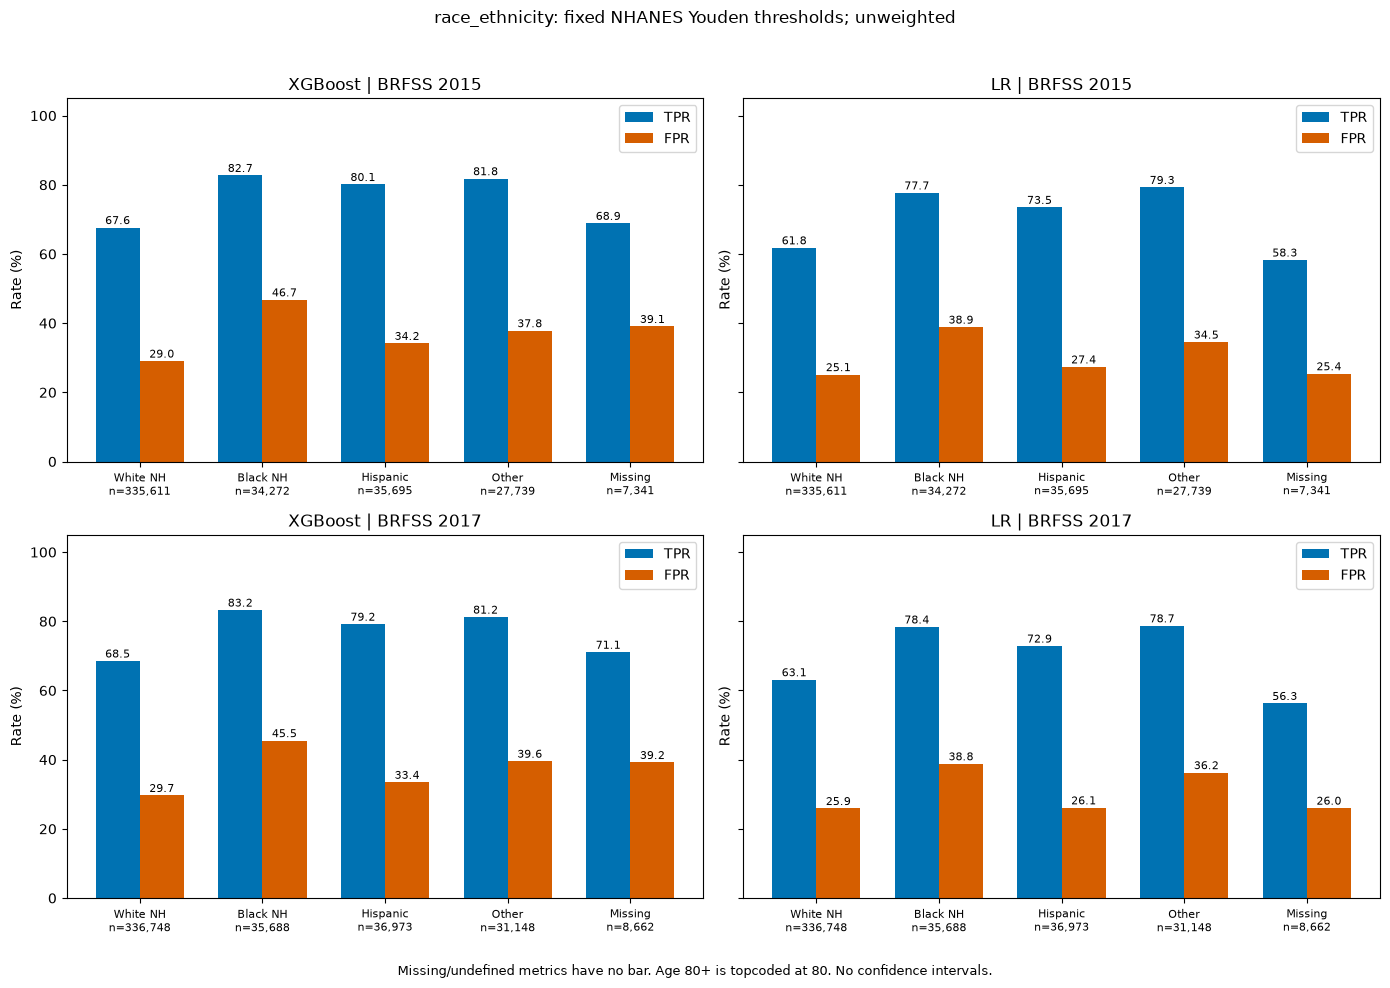

,year,attribute,group,n,n_positive,n_negative,positive_rate
5,2015,age,18-39,91408,2023,89385,0.022132
6,2015,age,40-59,144459,15220,129239,0.105359
7,2015,age,60-79,168102,33393,134709,0.198647
8,2015,age,80+,36689,6620,30069,0.180436
9,2015,age,Missing,0,0,0,NaN
25,2017,age,18-39,99769,2300,97469,0.023053
26,2017,age,40-59,140691,16128,124563,0.114634
27,2017,age,60-79,172999,35277,137722,0.203914
28,2017,age,80+,35760,6735,29025,0.188339
29,2017,age,Missing,0,0,0,NaN


,year,model,group,tpr,fpr,ppv,roc_auc,brier
5,2015,XGBoost,18-39,0.1068,0.0136,0.1512,0.7336,0.0371
6,2015,XGBoost,40-59,0.5938,0.2557,0.2147,0.7387,0.1707
7,2015,XGBoost,60-79,0.8106,0.5347,0.2731,0.7035,0.2623
8,2015,XGBoost,80+,0.6998,0.4717,0.2462,0.6580,0.2543
9,2015,XGBoost,Missing,NaN,NaN,NaN,NaN,NaN
15,2015,LR,18-39,0.0910,0.0129,0.1379,0.7265,0.0409
16,2015,LR,40-59,0.3725,0.1083,0.2882,0.7449,0.1395
17,2015,LR,60-79,0.7660,0.4665,0.2893,0.7130,0.2560
18,2015,LR,80+,0.9452,0.8342,0.1996,0.6724,0.3607
19,2015,LR,Missing,NaN,NaN,NaN,NaN,NaN


,year,model,attribute,tpr_gap_pp,fpr_gap_pp,ppv_gap_pp,predicted_positive_rate_gap_pp,equalized_odds_gap_pp
0,2015,XGBoost,age,70.38,52.11,12.20,57.39,70.38
1,2015,LR,age,85.42,82.13,15.14,83.96,85.42
2,2017,XGBoost,age,71.50,53.37,11.67,58.66,71.50
3,2017,LR,age,85.37,83.11,12.64,84.90,85.37


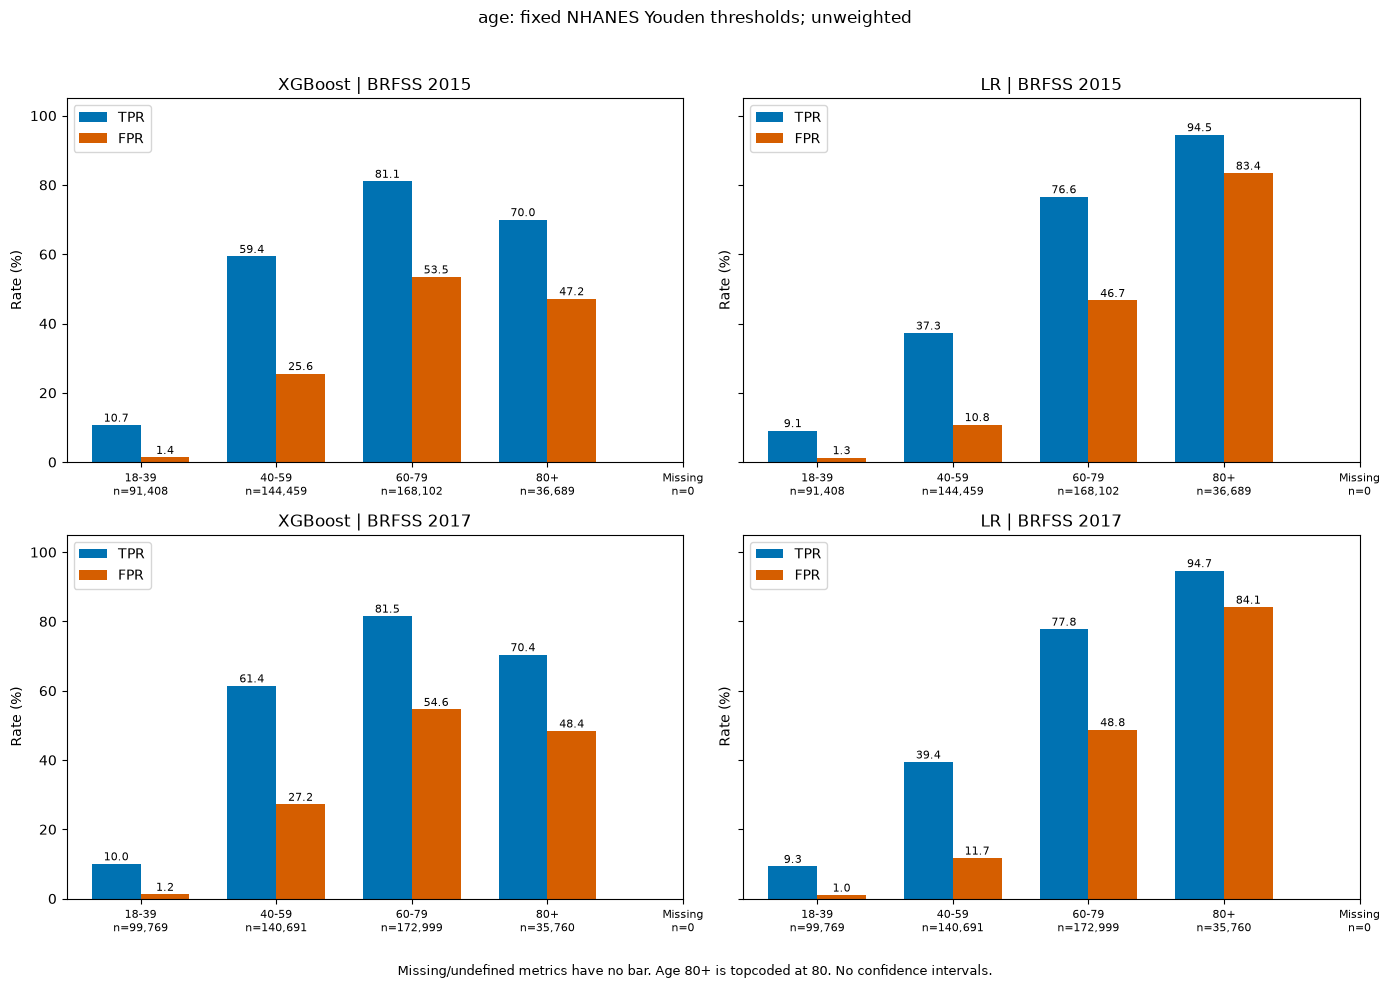

In [3]:
all_metrics = pd.DataFrame(rows)
output_paths = []
for attribute, groups in specs.items():
    metrics = all_metrics.loc[all_metrics["attribute"].eq(attribute)].copy()
    gaps = get_multigroup_metric_gaps(metrics, "group", groups)
    gaps.insert(2, "attribute", attribute)
    counts = metrics.loc[metrics["model"].eq("XGBoost"), ["year", "attribute", "group", "n", "n_positive", "n_negative", "positive_rate"]]
    for suffix, table in [("counts", counts), ("group_metrics", metrics), ("gaps_pp", gaps)]:
        path = result_dir / f"{attribute}_{suffix}.csv"
        table.to_csv(path, index=False, na_rep="NA")
        pd.testing.assert_frame_equal(pd.read_csv(path), table.reset_index(drop=True), check_dtype=False)
        output_paths.append(path)
    display(counts)
    display(metrics[["year", "model", "group", "tpr", "fpr", "ppv", "roc_auc", "brier"]].round(4))
    display(gaps.round(2))
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
    for i, year in enumerate([2015, 2017]):
        for j, model in enumerate(["XGBoost", "LR"]):
            ax = axes[i, j]
            table = metrics.query("year == @year and model == @model").set_index("group").loc[groups + ["Missing"]]
            x = np.arange(len(table))
            for offset, metric, color in [(-0.18, "tpr", "#0072B2"), (0.18, "fpr", "#D55E00")]:
                values = table[metric].to_numpy(dtype=float) * 100
                ax.bar(x + offset, values, width=0.36, label=metric.upper(), color=color)
                for pos, value in zip(x + offset, values):
                    if np.isfinite(value):
                        ax.text(pos, value + 1, f"{value:.1f}", ha="center", fontsize=8)
            ax.set(xticks=x, xticklabels=[f"{g}\nn={int(table.loc[g, 'n']):,}" for g in table.index],
                   ylim=(0, 105), ylabel="Rate (%)", title=f"{model} | BRFSS {year}")
            ax.tick_params(axis="x", labelsize=8)
            ax.legend()
    fig.suptitle(f"{attribute}: fixed NHANES Youden thresholds; unweighted")
    fig.tight_layout(rect=[0, 0.04, 1, 0.96])
    fig.text(0.5, 0.015, "Missing/undefined metrics have no bar. Age 80+ is topcoded at 80. No confidence intervals.", ha="center", fontsize=9)
    path = figure_dir / f"{attribute}_tpr_fpr.png"
    fig.savefig(path, dpi=180)
    output_paths.append(path)
    plt.show()
    plt.close(fig)



In [4]:
manifest = {
    "final_run_id": run_id, "attributes": specs,
    "age_bins": "[18,40), [40,60), [60,80), [80,infinity); source topcoded at 80",
    "missing_group": "reported separately; excluded from disparity comparisons",
    "gap_rule": "100 * (max - min) across all prespecified nonmissing groups; NA if any required metric undefined",
    "equalized_odds_gap": "max(TPR range, FPR range); NA if either undefined",
    "thresholds": {m: source_manifest["thresholds"][m]["youden"] for m in ["XGBoost", "LR"]},
    "survey_weighted": False, "confidence_intervals": False, "statistical_tests": False,
    "source_sha256": source_hashes,
    "utils_sha256": hashlib.sha256((project_dir / "src/utils.py").read_bytes()).hexdigest(),
    "output_sha256": {str(p.relative_to(project_dir)): hashlib.sha256(p.read_bytes()).hexdigest() for p in output_paths},
}
(result_dir / "race_age_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")


2638

### Nhận xét kết quả chủng tộc và tuổi

Equalized odds gap (điểm phần trăm; khoảng lớn nhất giữa các nhóm có thông tin):

| Đặc trưng | Mô hình | BRFSS 2015 | BRFSS 2017 |
|---|---|---:|---:|
| Chủng tộc | XGBoost | 17,70 | 15,85 |
| Chủng tộc | LR | 17,47 | 15,58 |
| Tuổi | XGBoost | 70,38 | 71,50 |
| Tuổi | LR | 85,42 | 85,37 |

Gap theo tuổi lớn ở cả hai mô hình. Tỷ lệ nhãn bệnh cũng khác nhau rõ rệt: khoảng 2,2–2,3% ở tuổi 18-39 và 19,9–20,4% ở tuổi 60-79. Cần đọc TPR và FPR từng nhóm cùng tỷ lệ bệnh, thay vì kết luận chỉ từ tỷ lệ dự đoán dương. LR có gap tuổi lớn hơn XGBoost dù gap giới tính nhỏ hơn trong phân tích trước; thứ hạng fairness phụ thuộc đặc trưng đánh giá.

Các bảng và biểu đồ nằm trong `results/fairness/54c463bbe9079503/` và `results/figures/fairness/54c463bbe9079503/`, với tiền tố `race_ethnicity_` và `age_`. Manifest riêng: `race_age_manifest.json`. Chưa có CI/kiểm định và chưa điều chỉnh thiết kế khảo sát; kết quả là đánh giá mô tả trên mẫu BRFSS.
